# Autoencoder: Eliminación de ruido
A partir del código suministrado, añadiremos ruido gaussiano a las imágenes de entrada. Entrenaremos un autoencoder para eliminar este ruido de las imágenes y las compararemos con las originales.

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [3]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5), (0.5))
    ])

mnist_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

data_loader = torch.utils.data.DataLoader(dataset=mnist_data,
                                          batch_size=64,
                                          shuffle=True)

mnist_data_valid = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

data_loader_valid = torch.utils.data.DataLoader(dataset=mnist_data_valid,
                                          batch_size=64,
                                          shuffle=True)            

In [4]:
dataiter = iter(data_loader)
images, labels = next(dataiter)
print(torch.min(images), torch.max(images))

tensor(-1.) tensor(1.)


In [5]:
def add_noise(inputs, noise_factor=0.3):
    noise = torch.randn_like(inputs) * noise_factor
    noisy_inputs = inputs + noise
    noisy_inputs = torch.clamp(noisy_inputs, -1.0, 1.0)

    return noisy_inputs    

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()        
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 7)
        )
        
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 7),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [ ]:
model = Autoencoder()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(),
                             lr=1e-3, 
                             weight_decay=1e-5)

In [16]:
from pathlib import Path

directorio_checkpoints = Path("checkpoints_DAE")
directorio_checkpoints.mkdir(exist_ok=True)

def entrenar_autoencoder(nombre, factores_entrenamiento, num_epochs=10, reanudar=True):
    modelo = Autoencoder()
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)
    nombre_archivo = nombre.lower().replace(" ", "_").replace("(", "").replace(")", "").replace(".", "_")
    ruta_checkpoint = directorio_checkpoints / f"{nombre_archivo}.pt"
    primera_epoca = 0

    if reanudar and ruta_checkpoint.exists():
        checkpoint = torch.load(ruta_checkpoint, map_location="cpu")
        modelo.load_state_dict(checkpoint["modelo"])
        optimizer.load_state_dict(checkpoint["optimizador"])
        primera_epoca = checkpoint["epoca"]
        print(f"{nombre}: reanudando desde la época {primera_epoca}")
    else:
        print(nombre)

    for epoch in range(primera_epoca, num_epochs):
        for img, _ in data_loader:
            if factores_entrenamiento == "combinado":
                factor = torch.empty(1).uniform_(0.1, 0.9).item()
            else:
                factor = factores_entrenamiento

            noisy_img = add_noise(img, noise_factor=factor)
            recon = modelo(noisy_img)
            loss = criterion(recon, img)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        checkpoint = {
            "epoca": epoch + 1,
            "modelo": modelo.state_dict(),
            "optimizador": optimizer.state_dict(),
            "loss": loss.item(),
        }
        ruta_temporal = ruta_checkpoint.with_suffix(".tmp")
        torch.save(checkpoint, ruta_temporal)
        ruta_temporal.replace(ruta_checkpoint)
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f} (checkpoint guardado)")

    return modelo


modelos = {}
modelos["Ruido bajo (0.1)"] = entrenar_autoencoder("Ruido bajo (0.1)", 0.1)
modelos["Ruido moderado (0.3)"] = entrenar_autoencoder("Ruido moderado (0.3)", 0.3)
modelos["Ruido alto (0.7)"] = entrenar_autoencoder("Ruido alto (0.7)", 0.7)
modelos["Ruido combinado (0.1-0.9)"] = entrenar_autoencoder("Ruido combinado (0.1-0.9)", "combinado")


Ruido bajo (0.1)
Epoch [1/10], Loss: 0.9256 (checkpoint guardado)
Epoch [2/10], Loss: 0.9259 (checkpoint guardado)
Epoch [3/10], Loss: 0.9281 (checkpoint guardado)
Epoch [4/10], Loss: 0.9286 (checkpoint guardado)
Epoch [5/10], Loss: 0.8567 (checkpoint guardado)
Epoch [6/10], Loss: 0.8467 (checkpoint guardado)
Epoch [7/10], Loss: 0.8346 (checkpoint guardado)
Epoch [8/10], Loss: 0.8448 (checkpoint guardado)
Epoch [9/10], Loss: 0.8339 (checkpoint guardado)
Epoch [10/10], Loss: 0.8417 (checkpoint guardado)
Ruido moderado (0.3)
Epoch [1/10], Loss: 0.9266 (checkpoint guardado)
Epoch [2/10], Loss: 0.9195 (checkpoint guardado)
Epoch [3/10], Loss: 0.9248 (checkpoint guardado)
Epoch [4/10], Loss: 0.9283 (checkpoint guardado)
Epoch [5/10], Loss: 0.8523 (checkpoint guardado)
Epoch [6/10], Loss: 0.8442 (checkpoint guardado)
Epoch [7/10], Loss: 0.8379 (checkpoint guardado)
Epoch [8/10], Loss: 0.8352 (checkpoint guardado)
Epoch [9/10], Loss: 0.8440 (checkpoint guardado)
Epoch [10/10], Loss: 0.8529 (c

In [ ]:
factores_prueba = [0.3, 0.6, 0.9]
clean_imgs, _ = next(iter(data_loader_valid))
clean_imgs = clean_imgs[:4]
noisy_imgs_por_factor = {
    factor: add_noise(clean_imgs, noise_factor=factor)
    for factor in factores_prueba
}
criterion_eval = nn.MSELoss()
tabla_mse = []

for nombre_red, modelo in modelos.items():
    modelo.eval()
    fila = {"Red entrenada": nombre_red}

    with torch.no_grad():
        for factor in factores_prueba:
            noisy_imgs = noisy_imgs_por_factor[factor]
            recon_imgs = modelo(noisy_imgs)
            fila[f"Factor {factor:.1f}"] = criterion_eval(recon_imgs, clean_imgs).item()

    tabla_mse.append(fila)

print("MSE sobre las mismas 4 imágenes de validación")
encabezado = ["Red entrenada"] + [f"Factor {factor:.1f}" for factor in factores_prueba]
ancho_nombre = max(len(encabezado[0]), max(len(fila["Red entrenada"]) for fila in tabla_mse))
ancho_numero = max(len(titulo) for titulo in encabezado[1:])
print(f"{encabezado[0]:<{ancho_nombre}} | " + " | ".join(f"{titulo:>{ancho_numero}}" for titulo in encabezado[1:]))
for fila in tabla_mse:
    valores = " | ".join(f"{fila[f'Factor {factor:.1f}']:>{ancho_numero}.4f}" for factor in factores_prueba)
    print(f"{fila['Red entrenada']:<{ancho_nombre}} | {valores}")

MSE sobre las mismas 4 imágenes de validación
Red entrenada             | Factor 0.3 | Factor 0.6 | Factor 0.9
Ruido bajo (0.1)          |     0.8182 |     0.8262 |     0.8406
Ruido moderado (0.3)      |     0.8199 |     0.8250 |     0.8407
Ruido alto (0.7)          |     0.8231 |     0.8270 |     0.8322
Ruido combinado (0.1-0.9) |     0.8232 |     0.8275 |     0.8355


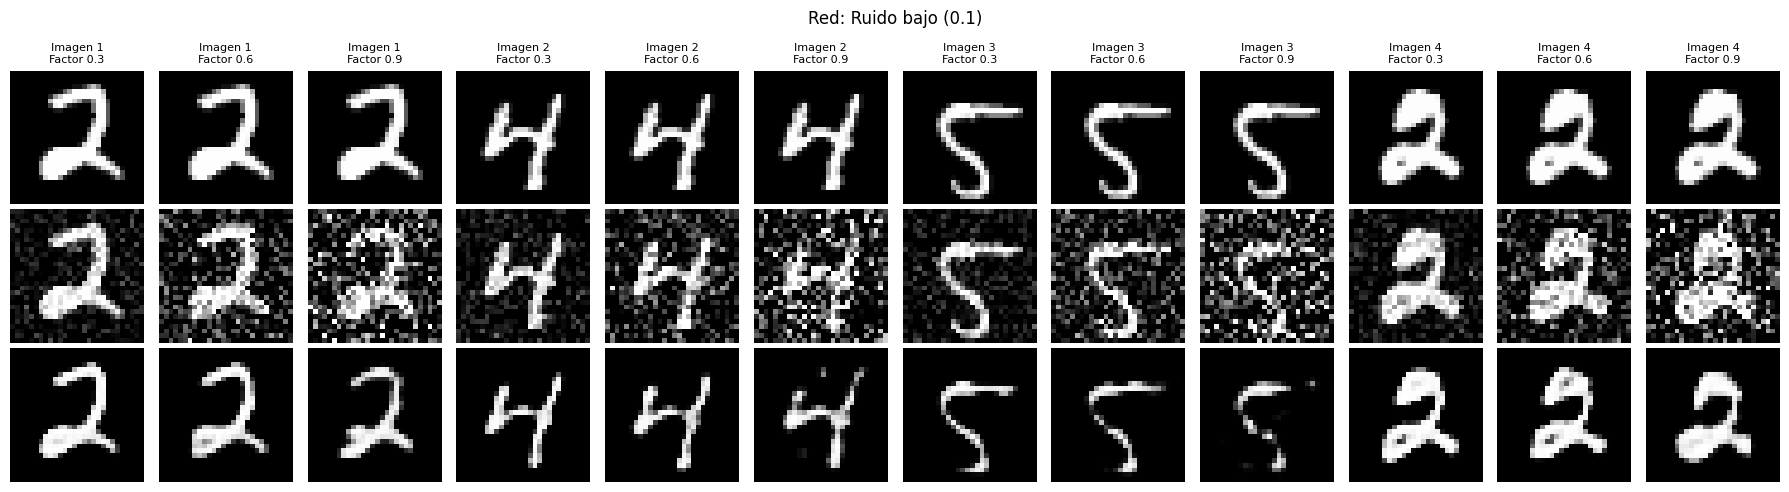

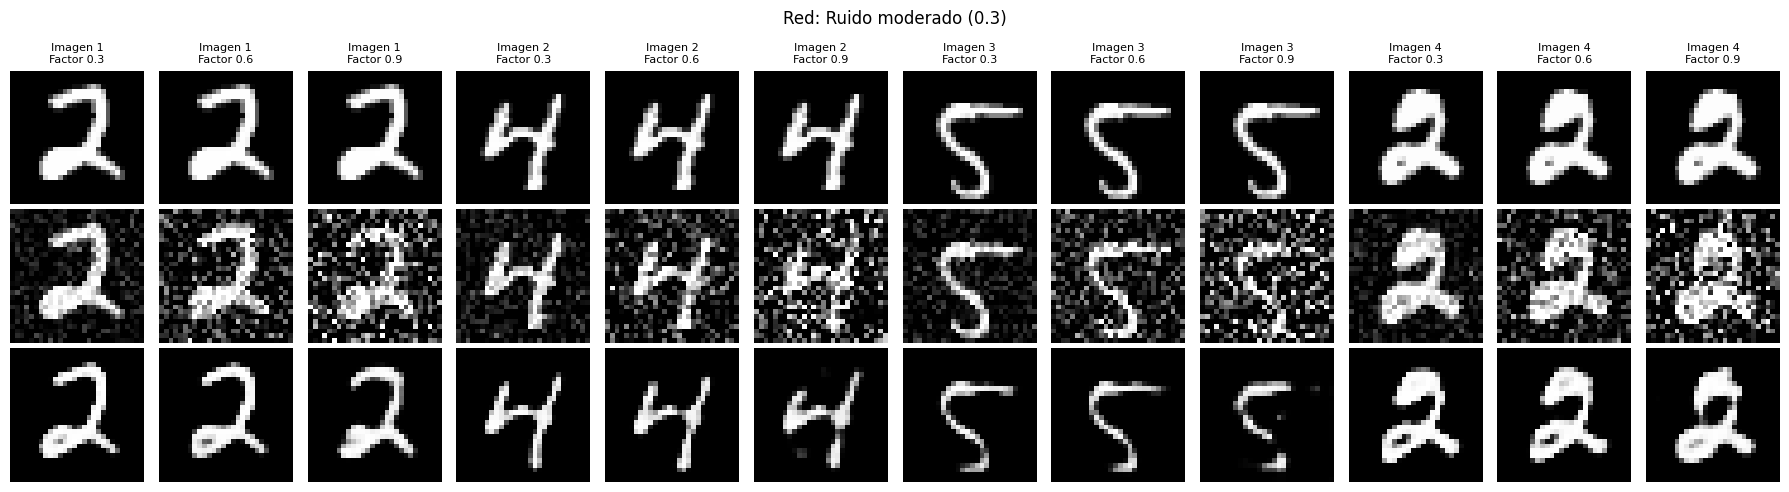

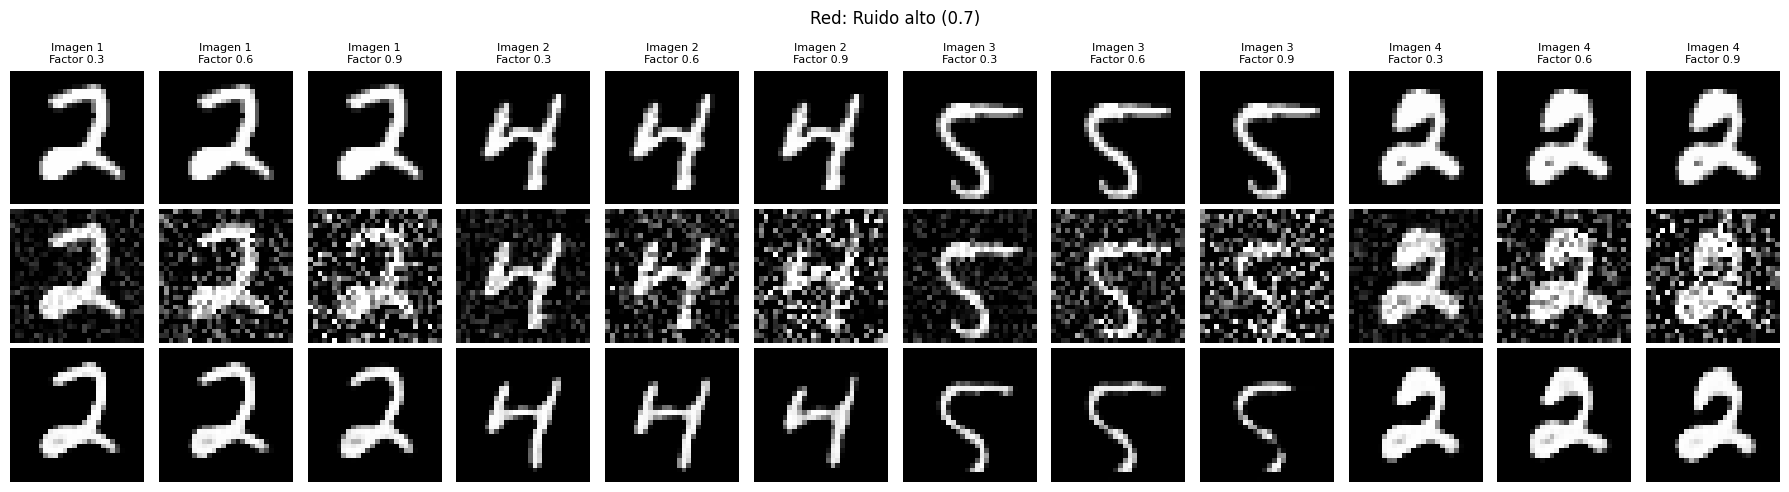

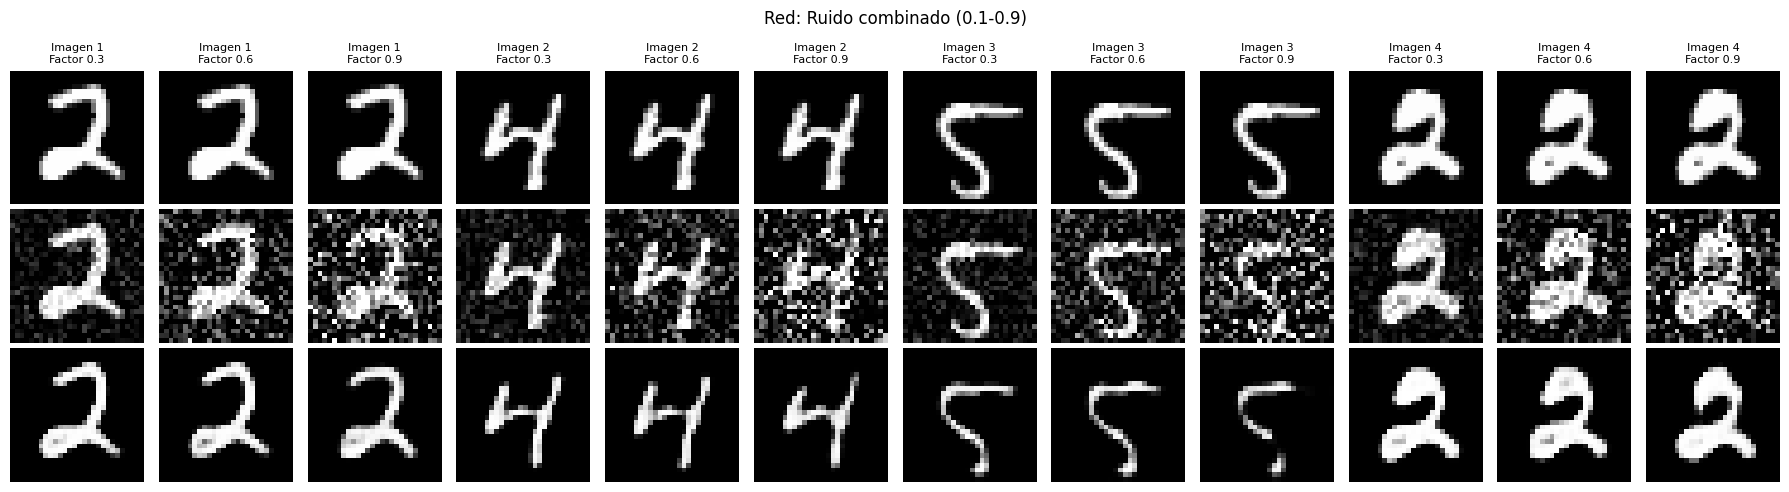

In [32]:
imagenes_visual = clean_imgs[:4]

for nombre_red, modelo in modelos.items():
    fig, axes = plt.subplots(
        3, len(imagenes_visual) * len(factores_prueba),
        figsize=(18, 5), squeeze=False
    )

    modelo.eval()
    with torch.no_grad():
        for indice_imagen in range(len(imagenes_visual)):
            for indice_factor, factor in enumerate(factores_prueba):
                columna = indice_imagen * len(factores_prueba) + indice_factor
                imagen_real = imagenes_visual[indice_imagen:indice_imagen + 1]
                imagen_ruidosa = noisy_imgs_por_factor[factor][indice_imagen:indice_imagen + 1]
                imagen_reconstruida = modelo(imagen_ruidosa)

                imagenes = [imagen_real, imagen_ruidosa, imagen_reconstruida]
                for fila, imagen in enumerate(imagenes):
                    axes[fila, columna].imshow(
                        imagen.squeeze().cpu().numpy(), cmap="gray"
                    )
                    axes[fila, columna].axis("off")

                axes[0, columna].set_title(
                    f"Imagen {indice_imagen + 1}\nFactor {factor:.1f}", fontsize=8
                )

    axes[0, 0].set_ylabel("Original", fontsize=10)
    axes[1, 0].set_ylabel("Con ruido", fontsize=10)
    axes[2, 0].set_ylabel("Reconstruida", fontsize=10)

    fig.suptitle("Red: " + nombre_red)
    plt.tight_layout()
    plt.show()